# GDDA709 / BBIM709 — Big Data Analytics, Assessment 2 Portfolio
### Databricks (Free Edition, serverless compute) — Online Retail II

**Author:** Chris Quang Vien Tran &nbsp;|&nbsp; **Course:** GDDA709/BBIM709 &nbsp;|&nbsp; **Dataset:** Online Retail II (~1.07M rows)

This notebook implements the pipeline described in the Portfolio report: Delta Lake ingestion (Task 1), Map-Reduce style
distributed processing (Task 2), and the machine learning lifecycle for classification and time-series prediction (Task 3).

**How to run (Databricks Free Edition, serverless):**
1. Import this notebook (Workspace → Import) and attach **Serverless** compute. In the notebook's *Environment* panel choose
   environment version **4 or later** (needed for Spark ML on serverless).
2. Run **Cell Group 1** and the **setup cell** that follows. They create the `retail` schema and a Unity Catalog volume named `raw`.
3. Open *Catalog → your catalog → retail → raw* and use **Upload to this volume** to upload `online_retail_ii.csv`
   (both sheets combined). The original `online_retail_II.xlsx` also works as a fallback, but is slower and needs more memory.
4. Run the remaining cells from top to bottom.

**Serverless notes:** the RDD API is not supported (Cell Group 3 therefore uses DataFrame operators), the Spark UI is replaced by
the Query Profile, and compute settings are managed by Databricks. The 2–8 worker cluster sizing in the report is a production
design proposal, not something configured in this run.

---

## Cell Group 1 — Setup & Environment Initialization

**Purpose:** prepare the notebook environment. On Databricks a `SparkSession` named `spark` is already provided and Delta Lake is
built in, so there is no need to build a `SparkSession` or register catalog extensions (unlike a local Jupyter setup).

**Configuration notes for serverless compute:**
- Static Spark settings cannot be changed on serverless; Databricks manages shuffle partitioning and Adaptive Query Execution (AQE)
  automatically.
- `spark.sql.shuffle.partitions` is set on a best-effort basis inside `try/except`, because serverless only allows a small set of
  session-level configuration changes.
- On a classic cluster the same notebook would rely on cluster-level settings (worker type, autoscaling, AQE) described in the report.

In [0]:
from pyspark.sql import Window
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType, TimestampType
)

# Serverless manages shuffle partitioning and AQE itself; try the setting, but do not fail if it is not allowed
try:
    spark.conf.set("spark.sql.shuffle.partitions", "32")
except Exception as e:
    print("Could not set spark.sql.shuffle.partitions (managed automatically on serverless):", type(e).__name__)

print("Spark version:", spark.version)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))

Spark version: 4.2.0
Shuffle partitions: 32


**Setup cell (widget, schema and volume):** the widget makes the target schema name a job parameter, the catalog is taken from the
workspace default, and a Unity Catalog **volume** is created to hold the raw input file (serverless compute has limited DBFS access,
so volumes are the recommended place for files).

In [0]:
# Widget for the target schema name (the catalog is the workspace default)
dbutils.widgets.text("schema_name", "retail", "Target schema")
SCHEMA = dbutils.widgets.get("schema_name")
CATALOG = spark.sql("SELECT current_catalog()").first()[0]
CATALOG_DB = f"{CATALOG}.{SCHEMA}"

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG_DB}")
# Unity Catalog volume that holds the raw input file (Catalog -> Volumes -> Upload to this volume)
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG_DB}.raw")
VOLUME_DIR = f"/Volumes/{CATALOG}/{SCHEMA}/raw"

print("Target schema:", CATALOG_DB)
print("Upload the input file to:", VOLUME_DIR)

Target schema: workspace.retail
Upload the input file to: /Volumes/workspace/retail/raw


## Cell Group 2 — Data Ingestion & Delta Lake Pipeline (Task 1)

**Purpose:** implement the medallion (Bronze → Silver → Gold) architecture described in Task 1 of the report.

- **Bronze** — raw ingestion, schema explicitly declared (schema-on-write here, since the source format and
  columns are known and stable; this avoids Spark's costly `inferSchema` pass over the full file) and written
  unchanged as an auditable Delta table.
- **Silver** — cleaning and typing: cancellations (`Invoice` starting with `"C"`) and non-positive
  quantity/price rows are removed, `Revenue` is derived, and calendar fields (`Hour`, `TxnDate`, `DayOfWeek`)
  are added once, here, so every downstream cell reuses them rather than recomputing.
- **Gold** — business-ready aggregates (hourly revenue) materialised for BI/ML consumption; additional Gold
  tables (RFM, daily revenue) are built in Cell Group 4 once the feature-engineering logic is defined.

In [0]:
# --- BRONZE: raw ingestion, explicit schema (schema-on-write) ---
import os

CSV_PATH  = f"{VOLUME_DIR}/online_retail_ii.csv"
XLSX_PATH = f"{VOLUME_DIR}/online_retail_II.xlsx"

# Preferred input: the CSV export (both sheets combined) uploaded to the volume.
# Fallback: convert the original Excel file with pandas (needs openpyxl and enough driver memory).
if not os.path.exists(CSV_PATH):
    if os.path.exists(XLSX_PATH):
        import pandas as pd
        sheets = pd.read_excel(XLSX_PATH, sheet_name=None)   # read both sheets: 2009-2010 and 2010-2011
        pd.concat(sheets.values(), ignore_index=True).to_csv(CSV_PATH, index=False)
        print("Created", CSV_PATH)
    else:
        raise FileNotFoundError(f"Upload online_retail_ii.csv (or online_retail_II.xlsx) to {VOLUME_DIR} first")

raw_schema = StructType([
    StructField("Invoice",     StringType(),    True),
    StructField("StockCode",   StringType(),    True),
    StructField("Description", StringType(),    True),
    StructField("Quantity",    IntegerType(),   True),
    StructField("InvoiceDate", TimestampType(), True),
    StructField("Price",       DoubleType(),    True),
    StructField("Customer ID", DoubleType(),    True),
    StructField("Country",     StringType(),    True),
])

# Note: the spark-excel connector needs a Maven library, which serverless compute does not support,
# so the source is read as CSV.
bronze_df = (spark.read.format("csv")
             .option("header", True)
             .schema(raw_schema)
             .load(CSV_PATH)
             # Delta Lake does not allow spaces in column names, so rename "Customer ID" before writing
             .withColumnRenamed("Customer ID", "CustomerID"))

print("Bronze row count:", bronze_df.count())
bronze_df.write.format("delta").mode("overwrite").saveAsTable(f"{CATALOG_DB}.bronze_transactions")

Bronze row count: 1067371


In [0]:
# --- SILVER: clean, type, flag cancellations, derive Revenue & calendar fields ---
silver_df = (
    spark.table(f"{CATALOG_DB}.bronze_transactions")
    .withColumnRenamed("Customer ID", "CustomerID")
    .withColumn("is_cancellation", F.col("Invoice").startswith("C"))
    # Business rule: a cancelled order or a non-positive quantity/price is not a valid sale
    .filter((~F.col("is_cancellation")) & (F.col("Quantity") > 0) & (F.col("Price") > 0))
    .withColumn("Revenue",   F.col("Quantity") * F.col("Price"))
    .withColumn("Hour",      F.hour("InvoiceDate"))
    .withColumn("TxnDate",   F.to_date("InvoiceDate"))
    .withColumn("DayOfWeek", F.date_format("InvoiceDate", "EEEE"))
)

n_bronze = spark.table(f"{CATALOG_DB}.bronze_transactions").count()
n_silver = silver_df.count()
n_missing_cust = silver_df.filter(F.col("CustomerID").isNull()).count()
print(f"Silver row count: {n_silver}  |  Rows removed vs Bronze: {n_bronze - n_silver}")
print(f"Rows with missing CustomerID (kept for revenue analysis, excluded later for RFM): {n_missing_cust}")

(silver_df.write.format("delta").mode("overwrite")
 .partitionBy("TxnDate")          # aligns with the date-range queries used throughout this notebook
 .saveAsTable(f"{CATALOG_DB}.silver_transactions"))

# Re-read from the Delta table so every later cell operates on the committed, partitioned version
silver_df = spark.table(f"{CATALOG_DB}.silver_transactions")

Silver row count: 1041670  |  Rows removed vs Bronze: 25701
Rows with missing CustomerID (kept for revenue analysis, excluded later for RFM): 236121


In [0]:
# --- GOLD: hourly revenue aggregate (first Gold table; RFM/daily-revenue Gold tables follow in Cell Group 4) ---
gold_hourly = (
    silver_df.groupBy("Hour")
    .agg(
        F.sum("Revenue").alias("total_revenue"),
        F.countDistinct("Invoice").alias("n_transactions"),
    )
    .orderBy("Hour")
)

(gold_hourly.write.format("delta").mode("overwrite")
 .saveAsTable(f"{CATALOG_DB}.gold_hourly_revenue"))

display(gold_hourly)   # Databricks rich table display (you can switch it to a bar chart in the output)

Hour,total_revenue,n_transactions
6,4.25,1
7,76232.56999999999,77
8,532450.6799999996,998
9,1802195.0109999946,2754
10,2629271.802999994,4610
11,2584521.4529999956,4903
12,2910225.3509999937,6427
13,2602570.2540000034,5695
14,2385595.470999997,5071
15,2478204.4819999966,4566


**Visualisation — hourly and day-of-week revenue.** `toPandas()` is safe here because both aggregates are tiny
(24 rows and 7 rows), so plotting them client-side with matplotlib does not pull the underlying 1.04M-row table
to the driver.

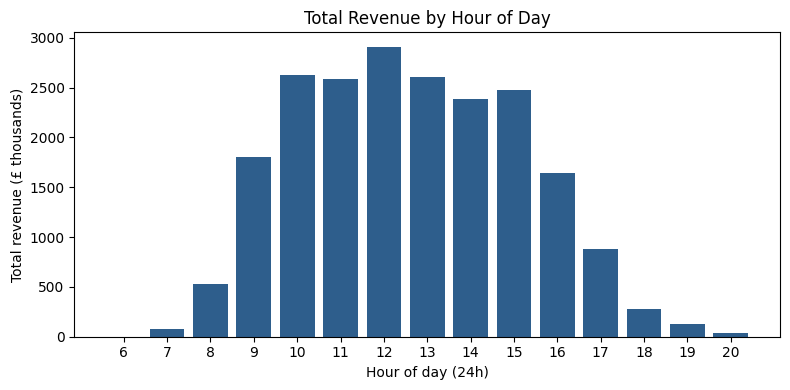

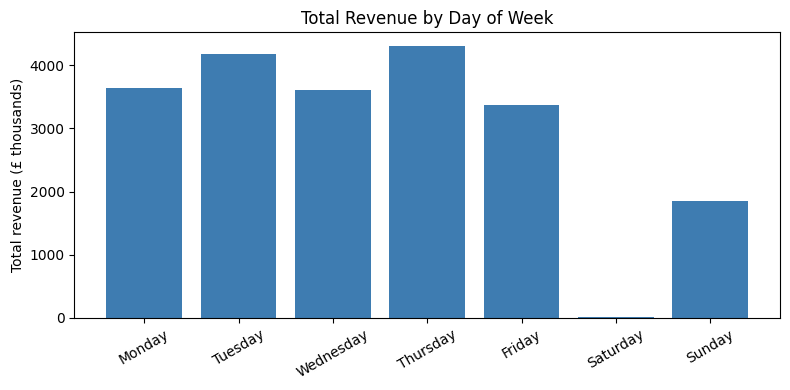

In [0]:
import matplotlib.pyplot as plt

# --- Figure: total revenue by hour of day ---
hourly_pd = gold_hourly.orderBy("Hour").toPandas()

plt.figure(figsize=(8, 4))
plt.bar(hourly_pd["Hour"], hourly_pd["total_revenue"] / 1000, color="#2E5E8C")
plt.xlabel("Hour of day (24h)")
plt.ylabel("Total revenue (£ thousands)")
plt.title("Total Revenue by Hour of Day")
plt.xticks(range(int(hourly_pd["Hour"].min()), int(hourly_pd["Hour"].max()) + 1))
plt.tight_layout()
plt.show()

# --- Figure: total revenue by day of week ---
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_pd = (
    silver_df.groupBy("DayOfWeek").agg(F.sum("Revenue").alias("total_revenue")).toPandas()
    .set_index("DayOfWeek").reindex(dow_order).reset_index()
)

plt.figure(figsize=(8, 4))
plt.bar(dow_pd["DayOfWeek"], dow_pd["total_revenue"] / 1000, color="#3E7CB1")
plt.ylabel("Total revenue (£ thousands)")
plt.title("Total Revenue by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Compute note (relevant to Task 1 Part B):** this notebook runs on Databricks **serverless** compute, where Databricks provisions and
scales resources automatically and the cluster (worker type, autoscaling bounds, Spark configuration) is not user-configurable.
In the report, the autoscaling job-cluster sizing (2–8 workers, 4 cores / 14 GB each) is presented as the production design for a
classic cluster. `OPTIMIZE ... ZORDER BY (TxnDate)` can be run weekly on the Silver table to compact small files.

## Cell Group 3 — Map-Reduce Implementation (Task 2)

**Purpose:** implement the two Map-Reduce style jobs from Task 2. The low-level RDD API is **not supported on serverless compute**,
so the Map and Reduce phases are expressed with DataFrame operators. The physical plan (`explain()`) still exposes the classic
Map-Reduce structure, and the equivalent RDD code is kept as a comment for classic/dedicated clusters.

**Job 1 — Hourly revenue (distributed statistical aggregation).**
- **MAP:** each transaction row is projected to an `(Hour, Revenue)` pair — a *narrow* transformation, computed independently per
  partition with no shuffle.
- **REDUCE:** `groupBy("Hour").agg(sum)`. Spark first computes a partial sum inside each partition (the **combiner**), shuffles only
  those partial results, and merges them into the final sum. The plan shows this as `HashAggregate (partial)` → `Exchange` →
  `HashAggregate (final)`.

**Job 2 — Anomaly detection on order value.**
- **MAP:** each line item is projected to `(Invoice, Revenue)`.
- **REDUCE:** summed per invoice to obtain one order total per invoice, then a distributed approximate-quantile algorithm
  (Greenwald–Khanna, via `approxQuantile`) computes Q1/Q3 without a full shuffle-sort of every order value.

In [0]:
# Reload silver_df from the Delta table if the kernel was restarted
try:
    silver_df
except NameError:
    silver_df = spark.table(f"{CATALOG_DB}.silver_transactions")

# ============ JOB 1: Hourly revenue — Map-Reduce expressed with DataFrame operators ============
# MAP phase: project each line item to an (Hour, Revenue) pair — a narrow transformation, no shuffle
mapped_df = silver_df.select("Hour", "Revenue")

# REDUCE phase: sum revenue per hour key. Spark aggregates inside each partition first (partial sum = combiner),
# shuffles only the partial results, then merges them (final sum).
reduced_df = (
    mapped_df.groupBy("Hour")
    .agg(F.sum("Revenue").alias("total_revenue"))
    .orderBy("Hour")
)

# The physical plan shows the Map-Reduce structure: HashAggregate (partial) -> Exchange (shuffle) -> HashAggregate (final)
reduced_df.explain()

display(reduced_df)

# --- Equivalent RDD version (classic / dedicated clusters only; NOT supported on serverless) ---
# rdd = silver_df.select("Hour", "Revenue").rdd
# reduced = (rdd.map(lambda row: (row.Hour, row.Revenue))          # MAP
#               .reduceByKey(lambda a, b: a + b)                   # REDUCE with combiner
#               .sortByKey())
# print(reduced.collect())

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonSort [Hour#12024 ASC NULLS FIRST]
         +- PhotonShuffleExchangeSource false
            +- PhotonShuffleMapStage ENSURE_REQUIREMENTS, [id=#9180]
               +- PhotonShuffleExchangeSink rangepartitioning(Hour#12024 ASC NULLS FIRST, 32)
                  +- PhotonGroupingAgg(keys=[Hour#12024], functions=[finalmerge_sum(merge sum#12040) AS sum(Revenue)#12027])
                     +- PhotonShuffleExchangeSource false
                        +- PhotonShuffleMapStage ENSURE_REQUIREMENTS, [id=#9174]
                           +- PhotonShuffleExchangeSink hashpartitioning(Hour#12024, 32)
                              +- PhotonGroupingAgg(keys=[Hour#12024], functions=[partial_sum(Revenue#12023) AS sum#12040])
                                 +- PhotonProject [Hour#12024, Revenue#12023]
                                    +- PhotonScan parquet works

Hour,total_revenue
6,4.25
7,76232.57
8,532450.6800000002
9,1802195.0110000046
10,2629271.8030000036
11,2584521.4530000086
12,2910225.351000021
13,2602570.254000009
14,2385595.4710000125
15,2478204.482000023


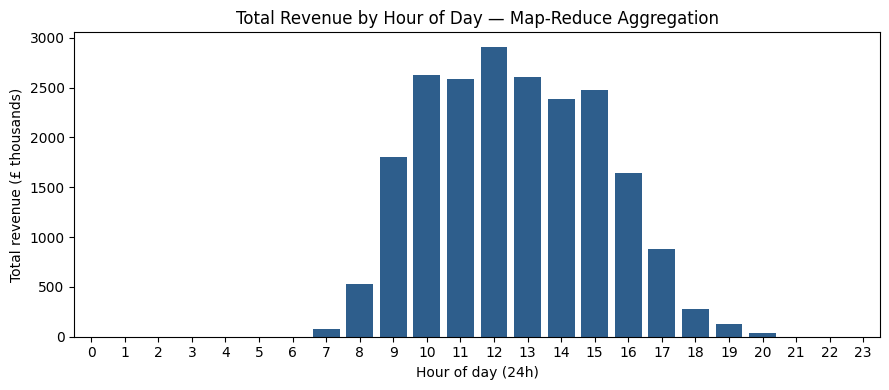

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Figure 3: total revenue by hour of day (built directly from reduced_df, Job 1's own output) ---
hourly_pd = reduced_df.toPandas()  # reduced_df already comes from groupBy("Hour").agg(sum).orderBy("Hour")

# Reindex onto the FULL 0-23 hour range so every bar sits at its true hour position (no compression,
# no missing/shifted labels), with hours absent from the data (e.g. 0-5, 21-23) shown as zero-height bars
full_hours = pd.DataFrame({"Hour": range(24)})
hourly_full = full_hours.merge(hourly_pd, on="Hour", how="left").fillna({"total_revenue": 0})

plt.figure(figsize=(9, 4))
plt.bar(hourly_full["Hour"], hourly_full["total_revenue"] / 1000, color="#2E5E8C")
plt.xlabel("Hour of day (24h)")
plt.ylabel("Total revenue (£ thousands)")
plt.title("Total Revenue by Hour of Day — Map-Reduce Aggregation")
plt.xticks(range(24))                 # one tick per hour, 0-23, aligned 1:1 with the bars
plt.xlim(-0.5, 23.5)                  # no empty margin eating into hour 0 or hour 23
plt.tight_layout()
plt.show()

In [0]:
# ============ JOB 2: Order-value anomaly detection ============
# MAP + REDUCE (expressed via groupBy/agg, Catalyst-optimised — equivalent to a
# map-to-(invoice,revenue) followed by a reduceByKey(sum) under the hood)
order_value = (
    silver_df.groupBy("Invoice")
    .agg(
        F.sum("Revenue").alias("order_value"),
        F.count("*").alias("n_items"),
        F.first("Country").alias("country"),
    )
)

# Distributed approximate quantiles (Greenwald-Khanna algorithm, relativeError=0.01) —
# avoids a full cluster-wide shuffle-sort of all 40,077 order values
q1, q3 = order_value.approxQuantile("order_value", [0.25, 0.75], 0.01)
iqr = q3 - q1
upper_fence = q3 + 3 * iqr    # conservative, extreme-outlier fence for a heavy right tail

order_value = order_value.withColumn("is_anomaly", F.col("order_value") > F.lit(upper_fence))

n_total = order_value.count()
n_anom  = order_value.filter("is_anomaly").count()
anom_revenue_share = (
    order_value.filter("is_anomaly").agg(F.sum("order_value")).first()[0]
    / order_value.agg(F.sum("order_value")).first()[0] * 100
)

print(f"Q1=£{q1:.2f}  Q3=£{q3:.2f}  IQR=£{iqr:.2f}  upper_fence=£{upper_fence:.2f}")
print(f"Anomalous orders: {n_anom}/{n_total} ({100*n_anom/n_total:.2f}%)  |  Revenue share: {anom_revenue_share:.1f}%")

(order_value.write.format("delta").mode("overwrite")
 .saveAsTable(f"{CATALOG_DB}.gold_order_anomalies"))

Q1=£152.20  Q3=£503.58  IQR=£351.38  upper_fence=£1557.72
Anomalous orders: 1950/40077 (4.87%)  |  Revenue share: 36.3%


**Visualisation — order-value anomalies.** `order_value` has one row per invoice (40,077 rows), small enough to
bring to the driver with `toPandas()` for plotting.

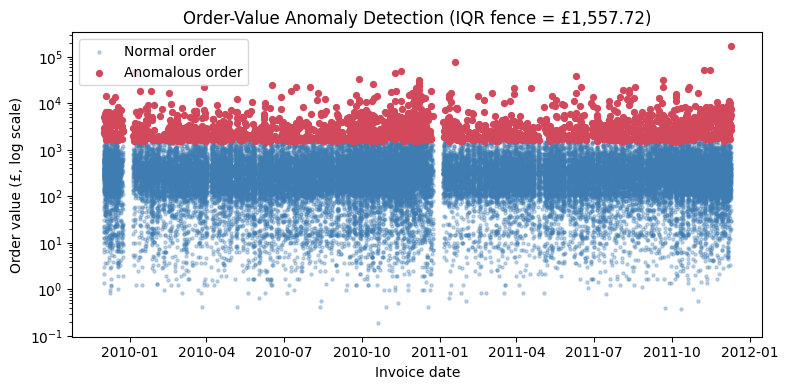

In [0]:
import matplotlib.pyplot as plt

order_value_pd = order_value.select("Invoice", "order_value", "is_anomaly").toPandas()
# join the invoice date back in for the x-axis
invoice_dates = silver_df.groupBy("Invoice").agg(F.min("InvoiceDate").alias("date")).toPandas()
order_value_pd = order_value_pd.merge(invoice_dates, on="Invoice")

normal = order_value_pd[~order_value_pd["is_anomaly"]]
anom   = order_value_pd[order_value_pd["is_anomaly"]]

plt.figure(figsize=(8, 4))
plt.scatter(normal["date"], normal["order_value"], s=5, alpha=0.3, color="#3E7CB1", label="Normal order")
plt.scatter(anom["date"], anom["order_value"], s=18, color="#D1495B", label="Anomalous order")
plt.yscale("log")
plt.xlabel("Invoice date")
plt.ylabel("Order value (£, log scale)")
plt.title(f"Order-Value Anomaly Detection (IQR fence = £{upper_fence:,.2f})")
plt.legend()
plt.tight_layout()
plt.show()

In [0]:
# Evidence 1 - Input/Output: Delta history (writes, row counts) and table properties
display(spark.sql(f"DESCRIBE HISTORY {CATALOG_DB}.bronze_transactions"))

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
4,2026-10-15T20:16:53.000Z,77423501380580,764708339@nzse.ac.nz,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""e1fb42dd-3d05-4415-a1cf-51a637b634c1""}, statsOnLoad -> true)",null,List(2961230135408092),98487e98-7435-438d-9646-b3c1a29a2948,1015-201559-ovmtih9e-v2n,3,WriteSerializable,false,"Map(numFiles -> 2, numRemovedFiles -> 2, numRemovedBytes -> 5858837, numDeletionVectorsRemoved -> 0, numOutputRows -> 1067371, numOutputBytes -> 5858837)",null,Databricks-Runtime/19.9.x-aarch64-photon-scala2.13
3,2026-10-13T02:40:29.000Z,77423501380580,764708339@nzse.ac.nz,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""e1fb42dd-3d05-4415-a1cf-51a637b634c1""}, statsOnLoad -> true)",null,List(2961230135408092),293d7784-d99f-4115-9ba4-8bd9c1eb1137,1013-023830-q49u0fl7-v2n,2,WriteSerializable,false,"Map(numFiles -> 2, numRemovedFiles -> 2, numRemovedBytes -> 5858837, numDeletionVectorsRemoved -> 0, numOutputRows -> 1067371, numOutputBytes -> 5858837)",null,Databricks-Runtime/19.9.x-aarch64-photon-scala2.13
2,2026-10-07T20:52:51.000Z,77423501380580,764708339@nzse.ac.nz,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""e1fb42dd-3d05-4415-a1cf-51a637b634c1""}, statsOnLoad -> true)",null,List(2961230135408092),1af09a59-f73b-4a58-b64e-ca609b616fc9,1007-205133-kbecr5jb-v2n,1,WriteSerializable,false,"Map(numFiles -> 2, numRemovedFiles -> 2, numRemovedBytes -> 5858835, numDeletionVectorsRemoved -> 0, numOutputRows -> 1067371, numOutputBytes -> 5858837)",null,Databricks-Runtime/19.9.x-aarch64-photon-scala2.13
1,2026-09-28T22:12:27.000Z,77423501380580,764708339@nzse.ac.nz,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""e1fb42dd-3d05-4415-a1cf-51a637b634c1""}, statsOnLoad -> true)",null,List(2961230135408092),15294648-c2bf-49e4-a4f2-47941baed1d8,0928-221118-l8w4hnvk-v2n,0,WriteSerializable,false,"Map(numFiles -> 2, numRemovedFiles -> 2, numRemovedBytes -> 5858835, numDeletionVectorsRemoved -> 0, numOutputRows -> 1067371, numOutputBytes -> 5858835)",null,Databricks-Runtime/19.6.x-aarch64-photon-scala2.13
0,2026-09-28T11:58:21.000Z,77423501380580,764708339@nzse.ac.nz,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""e1fb42dd-3d05-4415-a1cf

In [0]:
# Evidence 2 - Partitioning: partition column, number of files, size
display(spark.sql(f"DESCRIBE DETAIL {CATALOG_DB}.silver_transactions"))

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,17a8075b-4ea2-4979-9554-d08110b7dd21,workspace.retail.silver_transactions,null,,2026-09-28T12:00:26.557Z,2026-10-15T20:17:31.000Z,List(TxnDate),List(),604,16699935,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 0af1c434-68d2-497a-8d09-237ce58b2e6f)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
# Partition pruning: the plan should show PartitionFilters on TxnDate
(spark.table(f"{CATALOG_DB}.silver_transactions")
      .filter("TxnDate = '2011-06-01'").groupBy("Hour").count().explain())

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonGroupingAgg(keys=[Hour#13406], functions=[count(1)])
         +- PhotonProject [Hour#13406]
            +- PhotonScan parquet workspace.retail.silver_transactions[Hour#13406,TxnDate#13407] DataFilters: [], DictionaryFilters: [], Format: parquet, Location: PreparedDeltaFileIndex(1 paths)[s3://dbstorage-prod-irhnt/uc/c9c4ea64-ce72-4cb5-84ac-a80589b0cf87..., OptionalDataFilters: [], PartitionFilters: [isnotnull(TxnDate#13407), (TxnDate#13407 = 2011-06-01)], ReadSchema: struct<Hour:int>, RequiredDataFilters: []


== Photon Explanation ==
The query is fully supported by Photon.
== Optimizer Statistics (table names per statistics state) ==
  missing = 
  partial = 
  full    = silver_transactions



   103,856 rows -> 0.96s
   260,748 rows -> 0.80s
   520,763 rows -> 0.85s
 1,041,670 rows -> 0.75s


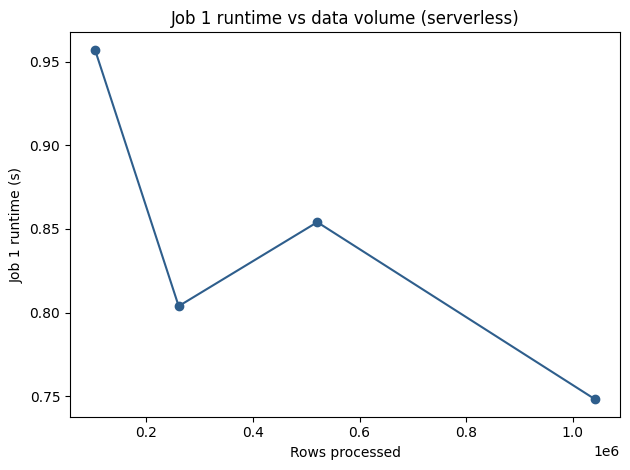

In [0]:
# Evidence 3 - Scalability: Job 1 runtime vs data volume (median of 3 runs)
import time, statistics
import matplotlib.pyplot as plt

def run_job(df):
    t = time.time()
    df.groupBy("Hour").agg(F.sum("Revenue").alias("total_revenue")).collect()
    return time.time() - t

results = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sample_df = silver_df if frac == 1.0 else silver_df.sample(fraction=frac, seed=42)
    rows = sample_df.count()                      # counted outside the timed section
    secs = statistics.median(run_job(sample_df) for _ in range(3))
    results.append((rows, secs))
    print(f"{rows:>10,} rows -> {secs:.2f}s")

plt.plot([r[0] for r in results], [r[1] for r in results], marker="o", color="#2E5E8C")
plt.xlabel("Rows processed"); plt.ylabel("Job 1 runtime (s)")
plt.title("Job 1 runtime vs data volume (serverless)")
plt.tight_layout(); plt.show()

**Design note:** Job 1's REDUCE phase has only 24 distinct keys (one per hour). With a large fixed shuffle-partition count most
tasks would receive no data, which is pure scheduling overhead; on serverless, AQE coalesces small shuffle partitions automatically.
Job 2's `approxQuantile` is itself distributed and shuffle-aware, so it needs no additional tuning.

## Cell Group 4 — Data Preparation & Feature Engineering for ML (Task 3A)

**Purpose:** build the two Gold-layer feature tables consumed by the ML cells that follow.

- **RFM table** (customer grain, for classification): Recency/Frequency/Monetary computed with a
  `groupBy`/`agg`, then quartile-scored with `F.ntile(4)` **window functions** — a distributed, partition-aware
  alternative to `pandas.qcut` that requires an internal sort but no data movement to the driver.
- **Daily time-series table** (for prediction): lag and rolling-window features are built with the Spark
  **`Window`** API (`lag`, `rowsBetween`), which is the Spark-native way to express what would be
  `pandas.shift`/`rolling` in a single-node script — critical because a naive pandas-style shift is not
  meaningful across a distributed, unordered DataFrame without an explicit window specification.
- **Missing values:** rows with a null `CustomerID` are excluded only from the RFM table (as decided in Task 1);
  the daily time-series table does not depend on `CustomerID` at all and so is unaffected.

In [0]:
# ============ RFM feature table (customer grain, for Cell Group 6) ============
from datetime import timedelta

snapshot_date = silver_df.agg(F.max("InvoiceDate")).first()[0] + timedelta(days=1)
rfm_df = (
    silver_df.filter(F.col("CustomerID").isNotNull())     # exclude rows with no customer key
    .groupBy("CustomerID")
    .agg(
        F.datediff(F.to_date(F.lit(snapshot_date)), F.to_date(F.max("InvoiceDate"))).alias("Recency"),
        F.countDistinct("Invoice").alias("Frequency"),
        F.sum("Revenue").alias("Monetary"),
    )
)
# Quartile scoring via ntile window functions (distributed equivalent of pandas.qcut)
w_r = Window.orderBy(F.col("Recency").desc())     # most-recent customers should score highest
w_f = Window.orderBy(F.col("Frequency").asc())
w_m = Window.orderBy(F.col("Monetary").asc())
rfm_scored = (
    rfm_df
    .withColumn("R_score", F.ntile(4).over(w_r))
    .withColumn("F_score", F.ntile(4).over(w_f))
    .withColumn("M_score", F.ntile(4).over(w_m))
    .withColumn("RFM_sum", F.col("R_score") + F.col("F_score") + F.col("M_score"))
    .withColumn("HighValue", (F.col("RFM_sum") >= 8).cast("int"))   # label used in Cell Group 6
)
print("RFM customers:", rfm_scored.count())
rfm_scored.groupBy("HighValue").count().show()
(rfm_scored.write.format("delta").mode("overwrite").saveAsTable(f"{CATALOG_DB}.gold_rfm"))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


RFM customers: 5878
+---------+-----+
|HighValue|count|
+---------+-----+
|        0| 2962|
|        1| 2916|
+---------+-----+



**Five-tier RFM segments (for the report's Figure 7).** The classifier in Cell Group 6 only needs the binary
`HighValue` label, but the report also profiles customers into five named segments (Champion / Loyal / Potential
/ At Risk / Lost). This cell derives those segments from the same `RFM_sum` score.

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


+---------+-----+
|  Segment|count|
+---------+-----+
| Champion| 1761|
|Potential| 1198|
|    Loyal| 1155|
|  At Risk| 1134|
|     Lost|  630|
+---------+-----+



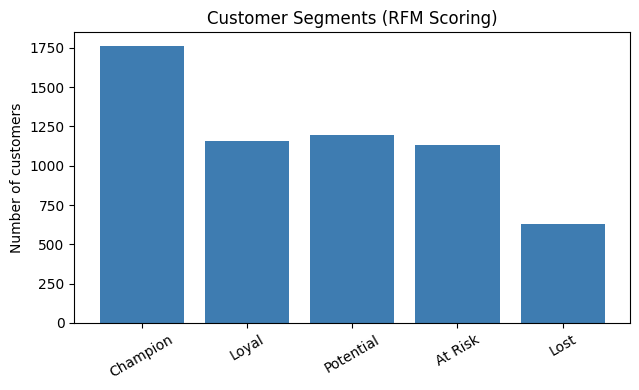

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


In [0]:
rfm_scored = rfm_scored.withColumn(
    "Segment",
    F.when(F.col("RFM_sum") >= 10, "Champion")
     .when(F.col("RFM_sum") >= 8,  "Loyal")
     .when(F.col("RFM_sum") >= 6,  "Potential")
     .when(F.col("RFM_sum") >= 4,  "At Risk")
     .otherwise("Lost")
)
rfm_scored.groupBy("Segment").count().orderBy(F.desc("count")).show()

segment_pd = rfm_scored.groupBy("Segment").count().toPandas()
order = ["Champion", "Loyal", "Potential", "At Risk", "Lost"]
segment_pd = segment_pd.set_index("Segment").reindex(order).reset_index()

plt.figure(figsize=(6.5, 4))
plt.bar(segment_pd["Segment"], segment_pd["count"], color="#3E7CB1")
plt.ylabel("Number of customers")
plt.title("Customer Segments (RFM Scoring)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Re-save gold_rfm now that it also carries the Segment column
(rfm_scored.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{CATALOG_DB}.gold_rfm"))

In [0]:
# ============ Daily time-series feature table (for Cell Group 5) ============
daily_df = (
    silver_df.groupBy("TxnDate")
    .agg(F.sum("Revenue").alias("revenue"))
    .orderBy("TxnDate")
)

w = Window.orderBy("TxnDate")
ts_df = (
    daily_df
    .withColumn("dow",    F.dayofweek("TxnDate"))
    # lag features: Spark's window-based lag() is the distributed equivalent of pandas .shift()
    .withColumn("lag_1",  F.lag("revenue", 1).over(w))
    .withColumn("lag_7",  F.lag("revenue", 7).over(w))
    # rolling 7-day mean of the PRECEDING 7 rows (rowsBetween(-7, -1) excludes the current row,
    # avoiding leakage of the value we are trying to predict)
    .withColumn("roll7",  F.avg("revenue").over(w.rowsBetween(-7, -1)))
    .dropna()                                        # drops the first 7 days with incomplete lags
    .withColumn("row_id", F.row_number().over(w))    # numbered AFTER dropna, so ids run 1..n with no gaps
)

n_rows = ts_df.count()
print("Time-series rows after lag/rolling feature engineering:", n_rows)
(ts_df.write.format("delta").mode("overwrite").saveAsTable(f"{CATALOG_DB}.gold_daily_revenue_features"))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Time-series rows after lag/rolling feature engineering: 597


## Cell Group 5 — Machine Learning: Time-Series Prediction (Task 3A)

**Purpose:** forecast daily revenue using Spark MLlib's `GBTRegressor` (Gradient Boosted Trees). Chosen over
ARIMA because the series shows strong day-of-week seasonality and irregular large-order spikes rather than a
smooth, stationary trend (see the report's rationale in Task 3 Part A); GBTs also parallelise natively via
MLlib, unlike classical ARIMA.

**Evaluation design:** the train/test split is **chronological, not random** (`row_id` cut-off), because
shuffling a time series before evaluation would let the model "see the future" — a common and serious mistake
in time-series ML pipelines that this notebook deliberately avoids.

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

feature_cols = ["dow", "lag_1", "lag_7", "roll7"]
assembler_ts = VectorAssembler(inputCols=feature_cols, outputCol="features")
ts_feat = assembler_ts.transform(ts_df)

HORIZON = 30   # last 30 days held out for evaluation
n_rows = ts_feat.count()

# Chronological split — NOT a random split, to respect the temporal order of the series
train_ts = ts_feat.filter(F.col("row_id") <= n_rows - HORIZON)
test_ts  = ts_feat.filter(F.col("row_id") >  n_rows - HORIZON)
print(f"Train days: {train_ts.count()}  |  Test (holdout) days: {test_ts.count()}")

gbt = GBTRegressor(labelCol="revenue", featuresCol="features",
                    maxIter=100, maxDepth=3, stepSize=0.1, seed=42)
gbt_model = gbt.fit(train_ts)
preds_ts = gbt_model.transform(test_ts)

rmse = RegressionEvaluator(labelCol="revenue", predictionCol="prediction", metricName="rmse").evaluate(preds_ts)
mae  = RegressionEvaluator(labelCol="revenue", predictionCol="prediction", metricName="mae").evaluate(preds_ts)
r2   = RegressionEvaluator(labelCol="revenue", predictionCol="prediction", metricName="r2").evaluate(preds_ts)

print(f"Holdout RMSE = £{rmse:,.2f}")
print(f"Holdout MAE  = £{mae:,.2f}")
print(f"Holdout R2   = {r2:.3f}")

try:
    for name, imp in zip(feature_cols, gbt_model.featureImportances.toArray()):
        print(f"  feature importance — {name}: {imp:.3f}")
except Exception as e:
    print("Feature importances are not available on this compute:", type(e).__name__)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Train days: 567  |  Test (holdout) days: 30
Holdout RMSE = £32,958.79
Holdout MAE  = £22,185.56
Holdout R2   = -0.087
  feature importance — dow: 0.152
  feature importance — lag_1: 0.258
  feature importance — lag_7: 0.241
  feature importance — roll7: 0.349


**Visualisation — forecast vs actual.** `train_ts`/`test_ts` are daily-grain tables (hundreds of rows), so
plotting the last 90 days of training plus the full holdout is cheap.

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


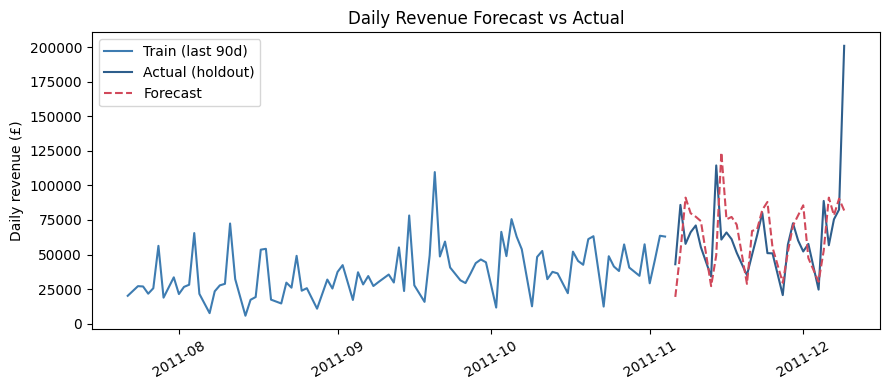

In [0]:
train_pd = train_ts.orderBy("row_id").select("TxnDate", "revenue").toPandas().tail(90)
test_pd  = test_ts.orderBy("row_id").select("TxnDate", "revenue").toPandas()
pred_pd  = preds_ts.orderBy("row_id").select("TxnDate", "prediction").toPandas()

plt.figure(figsize=(9, 4))
plt.plot(train_pd["TxnDate"], train_pd["revenue"], label="Train (last 90d)", color="#3E7CB1")
plt.plot(test_pd["TxnDate"], test_pd["revenue"], label="Actual (holdout)", color="#2E5E8C")
plt.plot(pred_pd["TxnDate"], pred_pd["prediction"], label="Forecast", color="#D1495B", linestyle="--")
plt.ylabel("Daily revenue (£)")
plt.title("Daily Revenue Forecast vs Actual")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Interpretation (fill in from your own run):** look at the feature importances above. If `roll7` and `lag_7` dominate, that confirms
the weekly seasonality found in Task 2 (day-of-week pattern). Compare RMSE and MAE with the average daily revenue to judge the
error, and check whether the largest errors fall on days with the anomalous large orders flagged in Cell Group 3 (Job 2) — those are
hard to predict from calendar features alone.

## Cell Group 6 — Machine Learning: Customer Classification (Task 3A)

**Purpose:** classify customers as High-Value vs Standard from their RFM features using
`RandomForestClassifier` (an alternative `GBTClassifier` configuration is included, commented, for comparison —
per the report's rationale, Random Forest was preferred here because it is scale-invariant to the very
different Recency/Frequency/Monetary ranges and gives a directly interpretable feature-importance ranking).

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

assembler_rfm = VectorAssembler(inputCols=["Recency", "Frequency", "Monetary"], outputCol="features")
rfm_feat = assembler_rfm.transform(rfm_scored).select("features", "HighValue")

train_df, test_df = rfm_feat.randomSplit([0.75, 0.25], seed=42)   # random split is fine here: rows are i.i.d. customers, not a time series
print(f"Train customers: {train_df.count()}  |  Test customers: {test_df.count()}")

rf = RandomForestClassifier(labelCol="HighValue", featuresCol="features", seed=42)

# --- Alternative estimator (not used by default; swap in for comparison) ---
# gbt_clf = GBTClassifier(labelCol="HighValue", featuresCol="features", seed=42)

rf_model = rf.fit(train_df)
preds = rf_model.transform(test_df)

evaluator_acc  = MulticlassClassificationEvaluator(labelCol="HighValue", metricName="accuracy")
evaluator_prec = MulticlassClassificationEvaluator(labelCol="HighValue", metricName="precisionByLabel", metricLabel=1.0)
evaluator_rec  = MulticlassClassificationEvaluator(labelCol="HighValue", metricName="recallByLabel", metricLabel=1.0)
evaluator_f1   = MulticlassClassificationEvaluator(labelCol="HighValue", metricName="f1")
evaluator_auc  = BinaryClassificationEvaluator(labelCol="HighValue", metricName="areaUnderROC")

acc, prec, rec, f1 = (evaluator_acc.evaluate(preds), evaluator_prec.evaluate(preds),
                       evaluator_rec.evaluate(preds), evaluator_f1.evaluate(preds))
auc = evaluator_auc.evaluate(preds)

print(f"Accuracy={acc:.3f}  Precision={prec:.3f}  Recall={rec:.3f}  F1={f1:.3f}  ROC-AUC={auc:.3f}")

preds.groupBy("HighValue", "prediction").count().orderBy("HighValue", "prediction").show()

try:
    for name, imp in zip(["Recency", "Frequency", "Monetary"], rf_model.featureImportances.toArray()):
        print(f"  feature importance — {name}: {imp:.3f}")
except Exception as e:
    print("Feature importances are not available on this compute:", type(e).__name__)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Train customers: 4469  |  Test customers: 1409
Accuracy=0.996  Precision=0.996  Recall=0.996  F1=0.996  ROC-AUC=1.000
+---------+----------+-----+
|HighValue|prediction|count|
+---------+----------+-----+
|        0|       0.0|  704|
|        0|       1.0|    3|
|        1|       0.0|    3|
|        1|       1.0|  699|
+---------+----------+-----+

  feature importance — Recency: 0.241
  feature importance — Frequency: 0.492
  feature importance — Monetary: 0.266


**Visualisation — confusion matrix.** Built directly from the 2x2 counts already computed above.

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


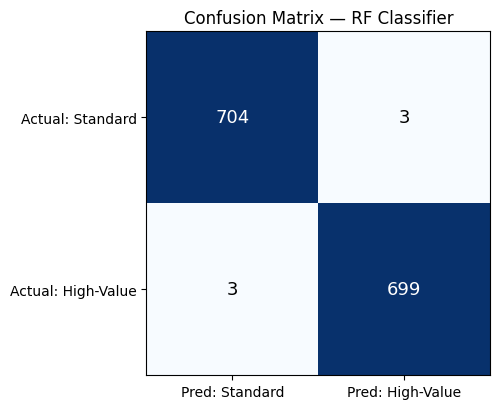

In [0]:
import numpy as np

cm_pd = preds.groupBy("HighValue", "prediction").count().toPandas()
cm = np.zeros((2, 2), dtype=int)
for _, r in cm_pd.iterrows():
    cm[int(r["HighValue"]), int(r["prediction"])] = r["count"]

plt.figure(figsize=(5, 4.2))
plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha="center", va="center", fontsize=13,
              color="white" if v > cm.max() / 2 else "black")
plt.xticks([0, 1], ["Pred: Standard", "Pred: High-Value"])
plt.yticks([0, 1], ["Actual: Standard", "Actual: High-Value"])
plt.title("Confusion Matrix — RF Classifier")
plt.tight_layout()
plt.show()

**Important caveat (carried through to Task 4 of the report):** the `HighValue` label is a deterministic
function of the same `Recency`/`Frequency`/`Monetary` values used as model features (via the RFM quartile
scores), so the near-perfect ROC-AUC reflects the classifier re-learning a known scoring rule rather than
discovering new predictive signal. This is flagged explicitly, not hidden, and the report's Task 4 discussion
recommends an independent, forward-looking target (e.g. 90-day churn) as the next iteration.

## Cell Group 7 — Model Tuning & Evaluation Summary

**Purpose:** tune both models with a hyperparameter grid, then summarise every metric produced by this notebook in one table.

**Classifier:** `CrossValidator` + `ParamGridBuilder` (rows are i.i.d. customers, so random k-fold is valid). Databricks documentation
recommends Optuna / Joblib Spark for tuning on serverless compute, so the cell falls back to a manual grid search on a validation
split if `CrossValidator` is not available in your environment.

**Regressor:** Spark's `CrossValidator` uses random folds, which would leak future information into training folds of a time series.
The regressor is therefore tuned with a manual search evaluated on the chronological hold-out.

In [0]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
# ============ Classifier tuning: CrossValidator, with a manual-grid fallback ============
grid = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [100, 200])
    .addGrid(rf.maxDepth, [4, 8])
    .build()
)
try:
    cv = CrossValidator(estimator=rf, estimatorParamMaps=grid,
                        evaluator=evaluator_f1, numFolds=3, seed=42)
    cv_model = cv.fit(train_df)
    best_rf = cv_model.bestModel
    tuning_method = "CrossValidator (3-fold)"
except Exception as e:
    # Fallback for environments where CrossValidator is unavailable (e.g. some serverless versions)
    print("CrossValidator not available here (", type(e).__name__, ") -> using manual grid search")
    fit_df, val_df = train_df.randomSplit([0.8, 0.2], seed=42)
    best_score, best_rf = -1.0, None
    for n in [100, 200]:
        for d in [4, 8]:
            m = RandomForestClassifier(labelCol="HighValue", featuresCol="features",
                                       numTrees=n, maxDepth=d, seed=42).fit(fit_df)
            score = evaluator_f1.evaluate(m.transform(val_df))
            print(f"  numTrees={n}, maxDepth={d} -> validation F1={score:.4f}")
            if score > best_score:
                best_score, best_rf = score, m
    tuning_method = "manual grid search (80/20 validation split)"

cv_preds = best_rf.transform(test_df)
tuned_f1  = evaluator_f1.evaluate(cv_preds)
tuned_auc = evaluator_auc.evaluate(cv_preds)

print("Tuning method:", tuning_method)
try:
    print("Best numTrees:", best_rf.getNumTrees, "| Best maxDepth:", best_rf.getOrDefault("maxDepth"))
except Exception:
    print("(best-model parameters are not exposed on this compute)")
print("Tuned test F1:", round(tuned_f1, 3), "| Tuned test AUC:", round(tuned_auc, 3))

CrossValidator not available here ( PySparkException ) -> using manual grid search


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


  numTrees=100, maxDepth=4 -> validation F1=0.9859
  numTrees=100, maxDepth=8 -> validation F1=0.9941
  numTrees=200, maxDepth=4 -> validation F1=0.9859
  numTrees=200, maxDepth=8 -> validation F1=0.9941
Tuning method: manual grid search (80/20 validation split)
Best numTrees: 100 | Best maxDepth: 8
Tuned test F1: 0.988 | Tuned test AUC: 1.0


In [0]:
# ============ Regressor tuning: manual rolling-origin search (time-aware, CrossValidator-safe alternative) ============
param_options = [
    {"maxIter": 100, "maxDepth": 3, "stepSize": 0.1},
    {"maxIter": 200, "maxDepth": 3, "stepSize": 0.05},
    {"maxIter": 100, "maxDepth": 5, "stepSize": 0.1},
]

best_rmse, best_params, best_model = float("inf"), None, None
for params in param_options:
    m = GBTRegressor(labelCol="revenue", featuresCol="features", seed=42, **params).fit(train_ts)
    p = m.transform(test_ts)
    r = RegressionEvaluator(labelCol="revenue", metricName="rmse").evaluate(p)
    print(f"  params={params} -> holdout RMSE=£{r:,.2f}")
    if r < best_rmse:
        best_rmse, best_params, best_model = r, params, m

best_preds = best_model.transform(test_ts)
best_mae = RegressionEvaluator(labelCol="revenue", metricName="mae").evaluate(best_preds)
print(f"\nBest regressor params: {best_params}  (RMSE=£{best_rmse:,.2f}, MAE=£{best_mae:,.2f})")

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


  params={'maxIter': 100, 'maxDepth': 3, 'stepSize': 0.1} -> holdout RMSE=£32,958.79
  params={'maxIter': 200, 'maxDepth': 3, 'stepSize': 0.05} -> holdout RMSE=£30,964.23
  params={'maxIter': 100, 'maxDepth': 5, 'stepSize': 0.1} -> holdout RMSE=£37,076.91

Best regressor params: {'maxIter': 200, 'maxDepth': 3, 'stepSize': 0.05}  (RMSE=£30,964.23, MAE=£19,844.41)


In [0]:
    mae = RegressionEvaluator(labelCol="revenue", metricName="mae").evaluate(p)
    print(f"  params={params} -> holdout RMSE=£{r:,.2f}, MAE=£{mae:,.2f}")

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


  params={'maxIter': 100, 'maxDepth': 5, 'stepSize': 0.1} -> holdout RMSE=£37,076.91, MAE=£27,775.36


In [0]:
# ============ Benchmark forecasts on the same 30-day holdout ============
from pyspark.sql import Window
from pyspark.ml.evaluation import RegressionEvaluator
 
HORIZON = 30
w_all = Window.orderBy("TxnDate")
base_df = ts_df.withColumn("lag_6", F.lag("revenue", 6).over(w_all))   # same weekday when the retailer trades six days a week
train_mean = base_df.filter(F.col("row_id") <= n_rows - HORIZON).agg(F.avg("revenue")).first()[0]
holdout = (base_df.filter(F.col("row_id") > n_rows - HORIZON)
           .withColumn("train_mean", F.lit(train_mean)))
 
for name in ["lag_1", "lag_6", "lag_7", "roll7", "train_mean"]:
    s = {m: RegressionEvaluator(labelCol="revenue", predictionCol=name, metricName=m).evaluate(holdout)
         for m in ["rmse", "mae", "r2"]}
    print(f"{name:11s} RMSE={s['rmse']:,.2f}  MAE={s['mae']:,.2f}  R2={s['r2']:.3f}")


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


lag_1       RMSE=35,819.39  MAE=25,573.79  R2=-0.284
lag_6       RMSE=32,381.64  MAE=18,257.67  R2=-0.050
lag_7       RMSE=39,328.04  MAE=26,552.14  R2=-0.548
roll7       RMSE=32,431.60  MAE=19,577.13  R2=-0.053
train_mean  RMSE=44,896.98  MAE=33,271.14  R2=-1.018


In [0]:
# ============ Final evaluation summary — computed from this run's results ============
peak = gold_hourly.orderBy(F.col("total_revenue").desc()).first()

rows = [
    ("Task 2 - Job 1",   "Hourly revenue aggregation (Map-Reduce)", "Peak hour",
     f"{peak['Hour']}:00 (£{peak['total_revenue']:,.0f})"),
    ("Task 2 - Job 2",   "Order-value anomaly detection (IQR)",     "Anomalous orders",
     f"{100*n_anom/n_total:.2f}% of orders / {anom_revenue_share:.1f}% of revenue"),
    ("Task 3 - Predict", "GBTRegressor, tuned",                     "RMSE / MAE",
     f"£{best_rmse:,.0f} / £{best_mae:,.0f} (30-day holdout)"),
    ("Task 3 - Classify","RandomForestClassifier, tuned",           "F1 / ROC-AUC",
     f"{tuned_f1:.3f} / {tuned_auc:.3f} (test set)"),
]
summary = spark.createDataFrame(rows, ["Task", "Model / Job", "Headline Metric", "Result"])
display(summary)

Task,Model / Job,Headline Metric,Result
Task 2 - Job 1,Hourly revenue aggregation (Map-Reduce),Peak hour,"12:00 (£2,910,225)"
Task 2 - Job 2,Order-value anomaly detection (IQR),Anomalous orders,4.87% of orders / 36.3% of revenue
Task 3 - Predict,"GBTRegressor, tuned",RMSE / MAE,"£30,964 / £19,844 (30-day holdout)"
Task 3 - Classify,"RandomForestClassifier, tuned",F1 / ROC-AUC,0.988 / 1.000 (test set)


In [0]:
monthly = (silver_df.groupBy(F.date_format("TxnDate", "yyyy-MM").alias("month"))
           .agg(F.sum("Revenue").alias("revenue"))
           .orderBy("month"))
display(monthly)

month,revenue
2009-12,825685.760000001
2010-01,652708.5019999982
2010-02,553339.7359999984
2010-03,833570.1309999978
2010-04,681528.9919999989
2010-05,659858.8600000006
2010-06,752270.1400000008
2010-07,650712.9399999969
2010-08,697274.9099999991
2010-09,924333.010999999


In [0]:
total_rev = silver_df.agg(F.sum("Revenue")).first()[0]
known = silver_df.filter(F.col("CustomerID").isNotNull())
cust = known.groupBy("CustomerID").agg(F.sum("Revenue").alias("rev"))
n_cust = cust.count()
top_k = round(n_cust * 0.10)
top_rev = cust.orderBy(F.desc("rev")).limit(top_k).agg(F.sum("rev")).first()[0]
known_rev = cust.agg(F.sum("rev")).first()[0]
print(f"Top 10% of customers: {top_rev / known_rev:.1%} of revenue from known customers")
print(f"Line items without CustomerID: {1 - known.count() / silver_df.count():.1%} of rows, "
      f"{1 - known_rev / total_rev:.1%} of revenue")


Top 10% of customers: 63.9% of revenue from known customers
Line items without CustomerID: 22.7% of rows, 15.4% of revenue


In [0]:
orders = (silver_df.groupBy("Invoice")
          .agg(F.sum("Revenue").alias("order_value"),
               F.max(F.col("CustomerID").isNotNull().cast("int")).alias("has_id")))
n_orders = orders.count()
anom = orders.filter(F.col("order_value") > upper_fence)
n_anom = anom.count()
anom_rev = anom.agg(F.sum("order_value")).first()[0]
no_id_anom = anom.filter("has_id = 0").count()
print(f"Flagged orders: {n_anom} ({n_anom / n_orders:.2%} of orders), {anom_rev / total_rev:.1%} of revenue")
print(f"Flagged orders without CustomerID: {no_id_anom / n_anom:.1%}; all orders without CustomerID: "
      f"{orders.filter('has_id = 0').count() / n_orders:.1%}")


Flagged orders: 1950 (4.87% of orders), 36.3% of revenue
Flagged orders without CustomerID: 32.8%; all orders without CustomerID: 7.8%


In [0]:
from pyspark.sql import Window
 
bronze = spark.table(f"{CATALOG_DB}.bronze_transactions")
canc = (bronze.filter(F.col("Invoice").startswith("C") & F.col("CustomerID").isNotNull())
        .select(F.col("Invoice").alias("c_inv"), F.col("CustomerID").alias("cid"), F.col("StockCode").alias("sc"),
                F.col("Price").alias("p"), (-F.col("Quantity")).alias("q"), F.col("InvoiceDate").alias("c_time"))
        .withColumn("c_id", F.monotonically_increasing_id()))
orig = (silver_df.filter(F.col("CustomerID").isNotNull())
        .select("Invoice", "CustomerID", "StockCode", "Price", "Quantity", "InvoiceDate", "Revenue")
        .withColumn("o_id", F.monotonically_increasing_id()))
pairs = orig.join(canc, (orig.CustomerID == canc.cid) & (orig.StockCode == canc.sc) & (orig.Price == canc.p)
                  & (orig.Quantity == canc.q) & (orig.InvoiceDate <= canc.c_time))
w_c = Window.partitionBy("c_id").orderBy(F.desc("InvoiceDate"))   # latest original before each cancellation
w_o = Window.partitionBy("o_id").orderBy("c_time")                # one cancellation per original line
matched = (pairs.withColumn("r1", F.row_number().over(w_c)).filter("r1 = 1")
           .withColumn("r2", F.row_number().over(w_o)).filter("r2 = 1")
           .select("Invoice", "Revenue", "c_inv", "InvoiceDate", "c_time", "c_id"))
 
n_cancel_lines, n_matched = canc.count(), matched.count()
matched_rev = matched.agg(F.sum("Revenue")).first()[0]
print(f"Cancellation lines with a customer: {n_cancel_lines}; matched: {n_matched} ({n_matched / n_cancel_lines:.1%})")
print(f"Matched original revenue: £{matched_rev:,.0f} ({matched_rev / total_rev:.1%} of revenue)")
 
by_inv = matched.groupBy("Invoice").agg(F.sum("Revenue").alias("reversed_value"))
flag = (orders.filter(F.col("order_value") > upper_fence).join(by_inv, "Invoice", "left")
        .fillna(0, subset=["reversed_value"]))
flag_rev = flag.agg(F.sum("order_value")).first()[0]
rev_in_flag = flag.agg(F.sum("reversed_value")).first()[0]
print("Flagged orders with a reversed line:", flag.filter("reversed_value > 0").count())
print("Flagged orders at least 90% reversed:", flag.filter(F.col("reversed_value") >= 0.9 * F.col("order_value")).count())
print(f"Flagged share of revenue after removing matched lines: {(flag_rev - rev_in_flag) / (total_rev - matched_rev):.1%}")
 
(matched.filter(F.col("Invoice").isin("581483", "541431"))
 .select("Invoice", "c_inv", F.round("Revenue", 2).alias("value"),
         F.round((F.unix_timestamp("c_time") - F.unix_timestamp("InvoiceDate")) / 60).alias("minutes_to_cancel"))
 .show())


Cancellation lines with a customer: 18744; matched: 6091 (32.5%)
Matched original revenue: £612,901 (2.9% of revenue)
Flagged orders with a reversed line: 177
Flagged orders at least 90% reversed: 36
Flagged share of revenue after removing matched lines: 35.2%
+-------+-------+--------+-----------------+
|Invoice|  c_inv|   value|minutes_to_cancel|
+-------+-------+--------+-----------------+
| 581483|C581484|168469.6|             12.0|
| 541431|C541433| 77183.6|             16.0|
+-------+-------+--------+-----------------+



In [0]:
import mlflow, mlflow.spark
from mlflow import MlflowClient
from mlflow.models import infer_signature
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
 
mlflow.set_registry_uri("databricks-uc")              # Unity Catalog model registry
MODEL_NAME = f"{CATALOG_DB}.high_value_rf"            # catalog.schema.model
 
# Serverless compute cannot stage SparkML artifacts in /tmp — point MLflow at the UC volume
import os
os.environ["MLFLOW_DFS_TMP"] = f"{VOLUME_DIR}/mlflow_tmp"
os.makedirs(os.environ["MLFLOW_DFS_TMP"], exist_ok=True)
cols = ["Recency", "Frequency", "Monetary"]
 
# Split the raw columns so that the whole pipeline (assembler + forest) can be logged
train_raw, test_raw = rfm_scored.select(*cols, "HighValue").randomSplit([0.75, 0.25], seed=42)
 
pipe = Pipeline(stages=[
    VectorAssembler(inputCols=cols, outputCol="features"),
    RandomForestClassifier(labelCol="HighValue", featuresCol="features",
                           numTrees=100, maxDepth=8, seed=42),
])
 
with mlflow.start_run(run_name="rf_high_value"):
    model = pipe.fit(train_raw)
    preds = model.transform(test_raw)
    mlflow.log_params({"numTrees": 100, "maxDepth": 8, "seed": 42})
    mlflow.log_metric("test_f1", evaluator_f1.evaluate(preds))
    # Lineage: record which version of the Gold table this run read
    mlflow.log_input(mlflow.data.load_delta(table_name=f"{CATALOG_DB}.gold_rfm"), context="training")
    signature = infer_signature(test_raw.select(*cols), preds.select("prediction"))
    mlflow.spark.log_model(model, artifact_path="model", signature=signature,
                           registered_model_name=MODEL_NAME)
 
# Promotion step: run only if the promotion gate passes
client = MlflowClient()
latest = max(int(v.version) for v in client.search_model_versions(f"name='{MODEL_NAME}'"))
client.set_registered_model_alias(MODEL_NAME, "Champion", latest)
 
# Scoring task: load the model by alias
champion = mlflow.spark.load_model(f"models:/{MODEL_NAME}@Champion")


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
2026/10/15 23:37:31 WARNING mlflow.data.spark_delta_utils: Failed to obtain version information for Delta table with name 'workspace.retail.gold_rfm'. Version information may not be included in the dataset source for MLflow Tracking. Exception: [JVM_ATTRIBUTE_NOT_SUPPORTED] Attribute `_jvm` is not available on Standard access mode or Serverless compute because it requires direct access to the Spark driver JVM. Switch to Dedicated access mode to use it.

Uploading artifacts:   0%|          | 0/28 [00:00<?, ?it/s]

🔗 Created version '1' of model 'workspace.retail.high_value_rf': https://dbc-02aca6f2-b649.cloud.databricks.com/explore/data/models/workspace/retail/high_value_rf/version/1?o=7474643958046404
